In [2]:
suppressMessages(library(DESeq2))
suppressMessages(library(ggplot2))
suppressMessages(library(cowplot))
suppressMessages(library(dplyr))
suppressMessages(library(apeglm))
suppressMessages(library(ggrepel))

In [3]:
in_dir <- "../../results/10_compare_with_public_data/05_Jianbo_Qing_JASN_2026"
out_dir <- "../../results/10_compare_with_public_data/06_de_analysis"

# create output directory if it doesn't exist
if (!dir.exists(out_dir)) {
   dir.create(out_dir, recursive = TRUE)
}

In [17]:
df_counts <- read.csv(glue::glue("{in_dir}/pbm.tsv"), 
row.names = 1, sep = "\t",
check.names = FALSE)

In [18]:
head(df_counts)

,Con1,Con2,Con3,LN1,LN2,LN3
,<int>,<int>,<int>,<int>,<int>,<int>
RP11-34P13.7,30,32,62,66,88,100
FO538757.2,2029,3399,3285,652,10,0
AP006222.2,207,228,385,230,77,59
RP4-669L17.10,18,19,27,28,20,6
RP5-857K21.4,1424,1474,2284,1513,519,316
RP11-206L10.4,4,0,4,3,0,4


In [19]:
coldata <- data.frame(
  condition = c(
    "Normal", "Normal", "Normal",
    "LN", "LN", "LN"),
  row.names = c(
    "Con1", "Con2", "Con3",
    "LN1", "LN2", "LN3")
)

In [20]:
coldata

,condition
,<chr>
Con1,Normal
Con2,Normal
Con3,Normal
LN1,LN
LN2,LN
LN3,LN


In [21]:
dds <- DESeqDataSetFromMatrix(countData = df_counts,
                              colData = coldata,
                              design = ~ condition)

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”


In [22]:
keep <- rowSums(counts(dds) >= 10) >= 3
dds <- dds[keep,]

In [23]:
dds

class: DESeqDataSet 
dim: 22203 6 
metadata(1): version
assays(1): counts
rownames(22203): RP11-34P13.7 FO538757.2 ... RP11-129M6.1 KIR3DL1
rowData names(0):
colnames(6): Con1 Con2 ... LN2 LN3
colData names(1): condition

In [24]:
dds <- DESeq(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [25]:
df_res <- results(dds, contrast = c("condition", "LN", "Normal")) %>%
    as.data.frame() %>%
    tidyr::drop_na()

write.csv(df_res, glue::glue("{out_dir}/de_results_LN_vs_Normal.csv"))

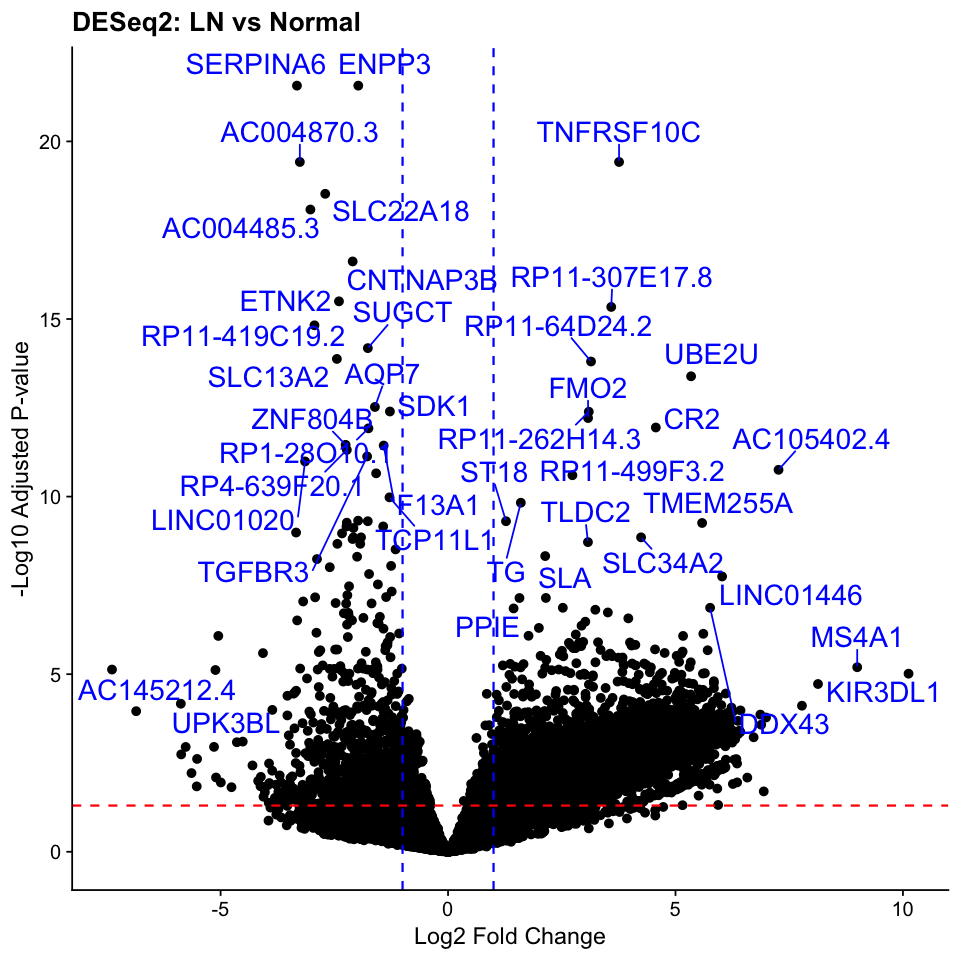

In [26]:
options(repr.plot.width = 8, repr.plot.height = 8)

df_text <- subset(df_res, padj < 0.0001 & abs(log2FoldChange) > 1)

p <- ggplot(data = df_res, aes(x = log2FoldChange, y = -log10(padj))) +
    geom_point() +
    geom_text_repel(data = df_text, aes(label = rownames(df_text)), vjust = -1, size = 6, color = "blue") +
    ggtitle("DESeq2: LN vs Normal") +
    xlab("Log2 Fold Change") +
    ylab("-Log10 Adjusted P-value") +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "red") +
    geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "blue") +
    theme_cowplot()

print(p)

In [27]:
options(repr.plot.width = 4, repr.plot.height = 4)

vsd <- vst(dds, blind = FALSE)  # or use rlog(dds)

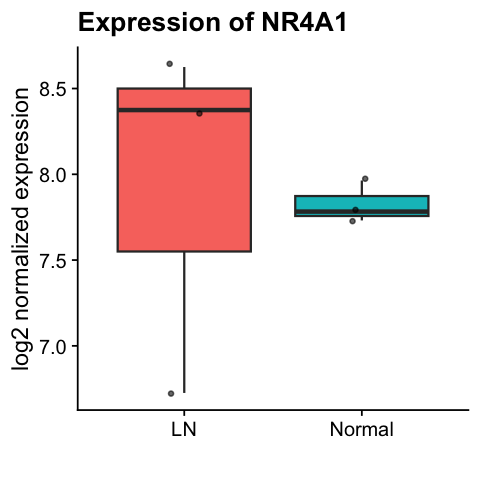

In [28]:
plot_df <- data.frame(
  expression = assay(vsd)["NR4A1", ],
  condition = colData(dds)$condition
)

ggplot(plot_df, aes(x = condition, y = expression, fill = condition)) +
  geom_boxplot() +
  geom_jitter(width = 0.1, size = 1, alpha = 0.6) +
  xlab("") +
  labs(title = paste("Expression of", "NR4A1"), y = "log2 normalized expression") +
  theme_cowplot() +
    theme(legend.position = "none")

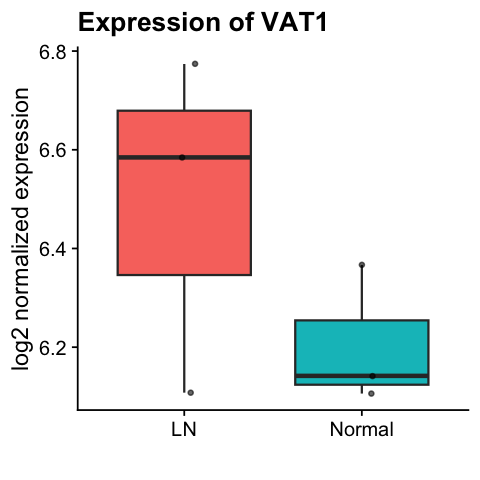

In [30]:
plot_df <- data.frame(
  expression = assay(vsd)["VAT1", ],
  condition = colData(dds)$condition
)

ggplot(plot_df, aes(x = condition, y = expression, fill = condition)) +
  geom_boxplot() +
  geom_jitter(width = 0.1, size = 1, alpha = 0.6) +
  xlab("") +
  labs(title = paste("Expression of", "VAT1"), 
  y = "log2 normalized expression") +
  theme_cowplot() +
    theme(legend.position = "none")